# Devoir maison n°1 :

## Réalisé par Jules Marin et Maxence Basset.

## Partie 1: Exploration de données

In [2]:
# Question 1.1 : 

import pandas as pd 

df = pd.read_csv("data/immobilier_dm_ml.csv")  # On charge les données.
cible = "prix_vente_keur"  # On nomme la cible.
variables = [c for c in df.columns if c not in ["id_bien", cible]]  # On liste les variables explicatives.

print("Nombre d'observations :", df.shape[0])  # On affiche le nombre d'observations.
print("Nombre de variables explicatives :", len(variables))  # On affiche le nombre de variables.

choix = [cible, "surface_habitable_m2", "distance_centre_ville_km", "qualite_quartier_indice"]  # On choisit quatre colonnes.
df[choix].agg(["mean", "std", "min", "max"]).T.round(3)  # On calcule les statistiques descriptives.

Nombre d'observations : 5000
Nombre de variables explicatives : 25


,mean,std,min,max
prix_vente_keur,249.980,5.715,227.451,277.187
surface_habitable_m2,0.003,1.009,-3.317,3.887
distance_centre_ville_km,-0.004,1.019,-3.451,3.858
qualite_quartier_indice,-0.007,1.019,-3.824,3.388


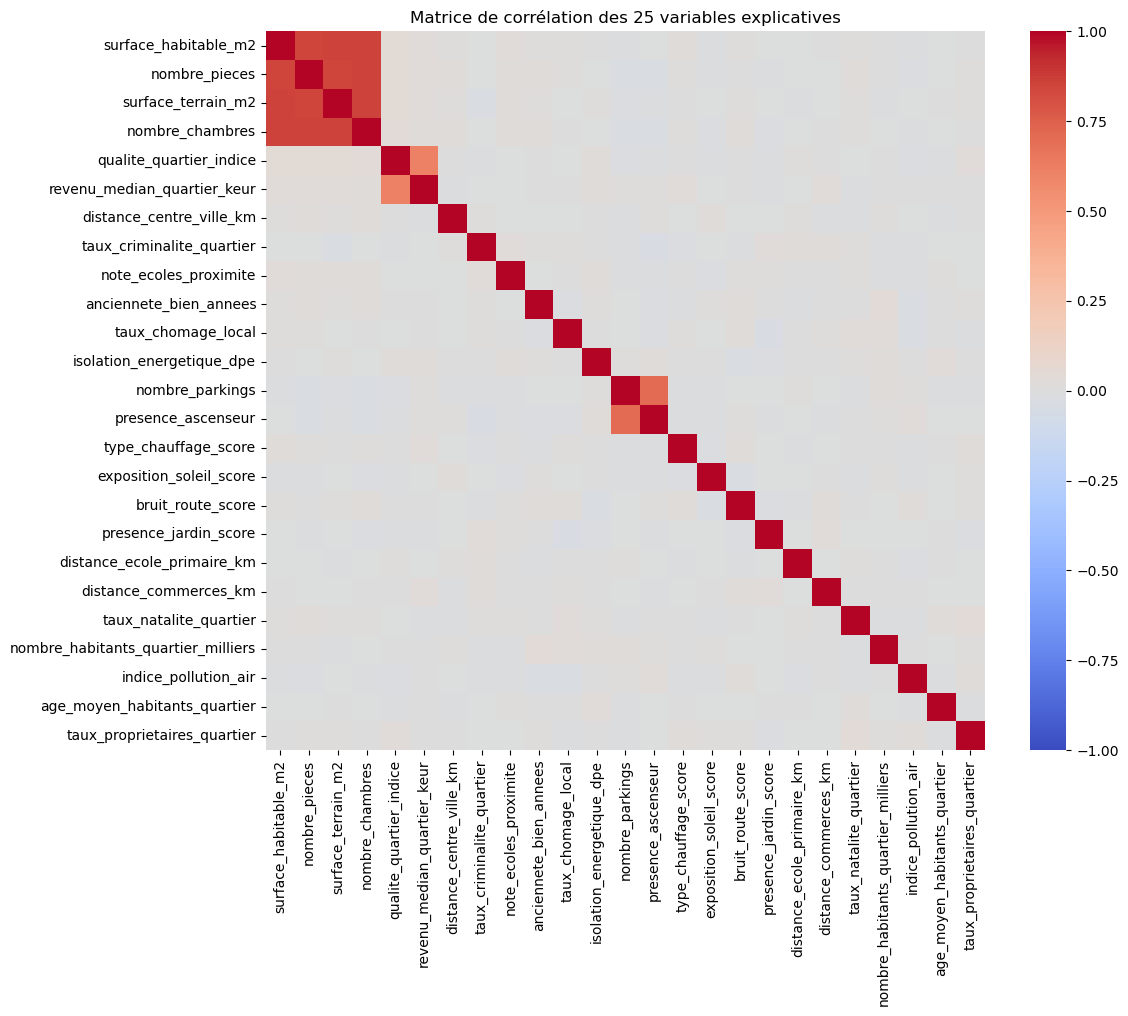

surface_habitable_m2     nombre_chambres                0.855
nombre_pieces            nombre_chambres                0.854
surface_habitable_m2     surface_terrain_m2             0.853
surface_terrain_m2       nombre_chambres                0.853
surface_habitable_m2     nombre_pieces                  0.850
nombre_pieces            surface_terrain_m2             0.848
nombre_parkings          presence_ascenseur             0.707
qualite_quartier_indice  revenu_median_quartier_keur    0.612
dtype: float64

In [3]:
# Question 1.2 :

import numpy as np  
import matplotlib.pyplot as plt  
import seaborn as sns  

corr = df[variables].corr()  # On calcule la matrice de corrélation.

plt.figure(figsize=(12, 10))  # On fixe la taille de la figure.
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, square=True)  # On trace la heatmap.
plt.title("Matrice de corrélation des 25 variables explicatives")  # On ajoute le titre.
plt.tight_layout()  # On ajuste les marges.
plt.show()  # On affiche la figure.

triangle = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))  # On garde le triangle supérieur.
paires = triangle.stack()  # On transforme la matrice en liste de paires.
paires = paires[paires.abs() > 0.5].sort_values(ascending=False)  # On filtre les paires avec |r| > 0,5.
paires.round(3)  # On affiche les paires retenues.

Huit paires dépassent le seuil |r| > 0,5, et elles forment trois groupes. Toutes les autres corrélations sont quasi nulles (|r| ≤ 0,04).

Groupe « taille du bien » (6 paires, r ≈ 0,85) : surface_habitable_m2, nombre_pieces, nombre_chambres et surface_terrain_m2 mesurent toutes la dimension du logement.

Surface habitable et nombre de pièces (0,850) : un logement plus grand est découpé en davantage de pièces.
Surface habitable et nombre de chambres (0,855) : la surface supplémentaire sert en priorité à ajouter des chambres.
Nombre de pièces et nombre de chambres (0,854) : les chambres sont comptées parmi les pièces.
Surface habitable et surface du terrain (0,853) : les grandes maisons sont construites sur de grandes parcelles.
Surface du terrain et nombre de pièces (0,848), surface du terrain et nombre de chambres (0,853) : ces liens découlent du précédent, un grand terrain accueille un grand logement donc plus de pièces et de chambres.

nombre_parkings et presence_ascenseur (0,707) : ces deux équipements caractérisent les immeubles collectifs récents ou de standing, qui disposent à la fois d'un ascenseur et d'un parking en sous-sol.

qualite_quartier_indice et revenu_median_quartier_keur (0,612) : les ménages aisés s'installent dans les quartiers les mieux cotés, et le revenu entre souvent dans la construction d'un indice composite de qualité.

Ces trois groupes annoncent un problème de colinéarité, surtout pour le groupe « taille » où quatre variables portent presque la même information.

In [4]:
# Question 1.3 : 

from sklearn.model_selection import train_test_split  # On importe la fonction de découpage.

RANDOM_STATE = 42  # On fixe la graine aléatoire.

X = df[variables]  # On isole les variables explicatives.
y = df[cible]  # On isole la cible.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)  # On découpe en 80 % / 20 %.

print("Apprentissage :", X_train.shape, "| Test :", X_test.shape)  # On affiche les dimensions.

Apprentissage : (4000, 25) | Test : (1000, 25)


L'ensemble d'apprentissage contient 4 000 observations et l'ensemble de test 1 000. L'ensemble de test sert à estimer l'erreur de généralisation sur des données jamais vues : si on l'utilisait pour choisir des variables ou régler un hyperparamètre, ces choix s'adapteraient à ses observations (fuite d'information) et l'erreur mesurée serait biaisée de façon optimiste. Toutes les décisions des parties 2 à 8 seront donc prises sur l'ensemble d'apprentissage, par validation croisée lorsque c'est nécessaire, et l'ensemble de test ne sera utilisé qu'une seule fois, à la Q9.1, pour comparer les modèles finaux.

## Partie 2 : Régression linéaire multiple et colinéarité

In [5]:
# Question 2.1 :

import statsmodels.api as sm

X_train_const = sm.add_constant(X_train)  # On ajoute la constante.
modele_complet = sm.OLS(y_train, X_train_const).fit()  # On ajuste le modèle complet.

print(f"R² : {modele_complet.rsquared:.4f}")  # On affiche le R².
print(f"R² ajusté : {modele_complet.rsquared_adj:.4f}")  # On affiche le R² ajusté.

R² : 0.7908
R² ajusté : 0.7894


Le modèle complet à 25 variables, ajusté sur les 4 000 observations d'apprentissage, donne R² = 0,7908 et R² ajusté = 0,7894. Il explique donc environ 79 % de la variance du prix de vente. Le R² ajusté, défini par 1 − [RSS/(n − d − 1)] / [TSS/(n − 1)] avec n = 4 000 et d = 25, pénalise le nombre de variables : l'écart avec le R² est très faible (0,0014) parce que n est très grand devant d.

In [6]:
# Question 2.2 :

from statsmodels.stats.outliers_influence import variance_inflation_factor  # On importe la fonction VIF.

vif = pd.Series([variance_inflation_factor(X_train_const.values, i) for i in range(1, X_train_const.shape[1])], index=variables)  # On calcule le VIF de chaque variable.

print(vif.sort_values(ascending=False).round(3))  # On affiche les VIF triés.
print("VIF > 5 :", vif[vif > 5].index.tolist())  # On liste les variables au-dessus du seuil.

nombre_chambres                       5.327
surface_habitable_m2                  5.170
surface_terrain_m2                    5.101
nombre_pieces                         4.996
presence_ascenseur                    2.061
nombre_parkings                       2.056
qualite_quartier_indice               1.592
revenu_median_quartier_keur           1.591
taux_criminalite_quartier             1.009
presence_jardin_score                 1.007
bruit_route_score                     1.007
taux_chomage_local                    1.007
isolation_energetique_dpe             1.007
indice_pollution_air                  1.006
exposition_soleil_score               1.006
type_chauffage_score                  1.006
taux_proprietaires_quartier           1.006
anciennete_bien_annees                1.005
taux_natalite_quartier                1.005
nombre_habitants_quartier_milliers    1.005
distance_commerces_km                 1.005
age_moyen_habitants_quartier          1.005
distance_centre_ville_km        

Le VIF de la variable j vaut 1/(1 − R²ⱼ), où R²ⱼ est le R² de la régression de cette variable sur les 24 autres.

Trois variables dépassent le seuil de 5 : nombre_chambres (5,33), surface_habitable_m2 (5,17) et surface_terrain_m2 (5,10). nombre_pieces est à 4,996, donc juste sous le seuil : comme ce seuil est conventionnel, on considère que les quatre variables du groupe « taille du bien » présentent une colinéarité forte.

Le résultat est cohérent avec la Q1.2, mais il la nuance :

Le groupe « taille » (r ≈ 0,85) ressort bien, car chaque variable est expliquée à environ 80 % par les trois autres (R²ⱼ ≈ 0,80, d'où VIF ≈ 5).
nombre_parkings et presence_ascenseur (r = 0,71) n'ont qu'un VIF de 2,06, et qualite_quartier_indice et revenu_median_quartier_keur (r = 0,61) un VIF de 1,59. Pour une paire isolée, le VIF vaut environ 1/(1 − r²), soit 2,0 et 1,6 : il faudrait |r| > 0,89 pour atteindre 5.
Les 17 autres variables ont un VIF proche de 1, ce qui confirme qu'elles sont quasi indépendantes des autres.

Le seuil |r| > 0,5 est donc plus sévère que le seuil VIF > 5 : les trois groupes de la Q1.2 sont colinéaires, mais seul le groupe « taille » l'est fortement.

**Question 2.3 :**

Le paradoxe n'est qu'apparent, car la qualité de prédiction et la précision des coefficients ne dépendent pas de la même chose.

Explication. La prédiction ŷ = Xβ̂ ne dépend que de la combinaison linéaire des variables, qui reste bien déterminée même quand elles sont colinéaires : le R² n'est donc pas affecté. En revanche, quand plusieurs variables portent presque la même information, les données ne permettent pas de dire laquelle est responsable de l'effet. Plusieurs répartitions très différentes des coefficients donnent presque la même RSS (les ellipses de niveau de la RSS sont très allongées). Cela se traduit par une variance gonflée : Var(β̂ⱼ) est multipliée par VIFⱼ, donc l'écart-type par √VIFⱼ.

Illustration. Notre modèle a une bonne capacité prédictive globale (R² = 0,79). Pourtant, dans le groupe « taille du bien » (VIF ≈ 5) :

Les écarts-types des quatre coefficients valent environ 0,093 à 0,096, contre 0,041 pour distance_centre_ville_km (VIF ≈ 1). Le rapport est d'environ 2,3, soit √5 : ces coefficients sont estimés avec une précision plus de deux fois moins bonne.
nombre_pieces, surface_terrain_m2 et nombre_chambres ont des coefficients quasi nuls (0,02 ; 0,01 ; 0,01) et non significatifs (p-valeurs de 0,79 à 0,92). L'intervalle de confiance à 95 % de nombre_pieces est d'environ [−0,16 ; 0,21] : même son signe est indéterminé.
Ces trois variables sont pourtant très liées à surface_habitable_m2 (r ≈ 0,85), qui a un effet fort sur le prix. Le modèle attribue tout l'effet « taille » à cette seule variable (3,04), et cette répartition entre les quatre est précisément ce que la colinéarité rend fragile.

On ne peut donc pas interpréter ces coefficients individuellement (« effet d'une pièce en plus, à surface égale »), alors que le modèle prédit bien dans son ensemble. C'est ce qui motive la sélection de variables et la régularisation des parties suivantes.

## Partie 3 : Sélection exhaustive (Best Subset Selection)

In [7]:
# Question 3.1 :

p = 25  # On fixe le nombre de variables candidates.
nb_modeles = 2 ** p  # On compte les sous-ensembles possibles.
temps_s = nb_modeles * 0.2e-3  # On calcule le temps total en secondes.

print("Nombre de sous-ensembles :", nb_modeles)  # On affiche le nombre de modèles.
print(f"Temps estimé : {temps_s:.0f} s, soit {temps_s / 3600:.2f} h")  # On affiche le temps estimé.

pool = ["surface_habitable_m2", "nombre_pieces", "surface_terrain_m2",
        "nombre_chambres", "qualite_quartier_indice", "revenu_median_quartier_keur",
        "distance_centre_ville_km", "taux_criminalite_quartier", "note_ecoles_proximite",
        "anciennete_bien_annees", "taux_chomage_local", "isolation_energetique_dpe",
        "nombre_parkings", "presence_ascenseur", "indice_pollution_air"]  # On définit le pool réduit de 15 variables.

print("Sous-ensembles avec le pool réduit :", 2 ** len(pool))  # On compte les modèles du pool réduit.

Nombre de sous-ensembles : 33554432
Temps estimé : 6711 s, soit 1.86 h
Sous-ensembles avec le pool réduit : 32768


Chaque variable est soit incluse, soit exclue du modèle : il y a donc 2ᵖ sous-ensembles distincts, ensemble vide et ensemble complet compris. On retrouve ce total en sommant, pour chaque taille k, les C(p, k) modèles à k variables : Σₖ C(p, k) = 2ᵖ.

Pour p = 25, cela représente 2²⁵ = 33 554 432 modèles. À 0,2 ms par modèle, le temps total est d'environ 6 711 secondes, soit 1 h 52 min.

Conclusion. Le calcul reste techniquement possible, mais il n'est pas praticable :

* Ce temps ne compte qu'un ajustement par modèle ; une validation croisée à 5 plis le multiplierait par 5 (plus de 9 heures).
* Le coût double à chaque variable ajoutée : environ 2,5 jours pour p = 30 et près de 7 ans pour p = 40. La méthode ne passe donc pas à l'échelle.

En restreignant la sélection à un pool de 15 variables, il ne reste que 2¹⁵ = 32 768 modèles, soit environ 6,6 secondes au même rythme.

In [8]:
# Question 3.2 :

import itertools  # On importe l'outil de combinaisons.
import time  # On importe le chronomètre.
from sklearn.linear_model import LinearRegression  # On importe la régression linéaire.

X_pool = X_train[pool].values  # On convertit le pool en tableau numpy.
y_tr = y_train.values  # On convertit la cible en tableau numpy.

def calculer_rss(indices):  # On définit le calcul de la RSS d'un sous-ensemble.
    if len(indices) == 0:  # On traite le modèle sans variable.
        return ((y_tr - y_tr.mean()) ** 2).sum()  # On renvoie la RSS de la constante seule.
    X_k = X_pool[:, list(indices)]  # On extrait les colonnes du sous-ensemble.
    modele = LinearRegression().fit(X_k, y_tr)  # On ajuste la régression.
    return ((y_tr - modele.predict(X_k)) ** 2).sum()  # On renvoie la RSS.

debut = time.time()  # On lance le chronomètre.
resultats = []  # On prépare la liste des résultats.
for k in range(len(pool) + 1):  # On parcourt les tailles de 0 à 15.
    combinaisons = list(itertools.combinations(range(len(pool)), k))  # On liste les sous-ensembles de taille k.
    rss = [calculer_rss(c) for c in combinaisons]  # On calcule la RSS de chaque sous-ensemble.
    i = int(np.argmin(rss))  # On repère la RSS minimale.
    resultats.append({"k": k, "nb_modeles": len(combinaisons), "RSS": rss[i], "variables": [pool[j] for j in combinaisons[i]]})  # On enregistre le meilleur modèle.

best_subset = pd.DataFrame(resultats).set_index("k")  # On range les résultats dans un tableau.
print(f"Temps de calcul : {time.time() - debut:.1f} s pour {best_subset['nb_modeles'].sum()} modèles")  # On affiche le temps de calcul.

pd.set_option("display.max_colwidth", None)  # On autorise l'affichage complet des listes.
best_subset.round(1)  # On affiche le meilleur modèle par taille.

Temps de calcul : 13.2 s pour 32768 modèles


,nb_modeles,RSS,variables
k,,,
0,1,131085.7,[]
1,15,90019.1,[surface_habitable_m2]
2,105,71796.4,"[surface_habitable_m2, qualite_quartier_indice]"
3,455,53672.9,"[surface_habitable_m2, qualite_quartier_indice, distance_centre_ville_km]"
4,1365,40515.4,"[surface_habitable_m2, qualite_quartier_indice, distance_centre_ville_km, taux_criminalite_quartier]"
5,3003,35078.5,"[surface_habitable_m2, qualite_quartier_indice, distance_centre_ville_km, taux_criminalite_quartier, note_ecoles_proximite]"
6,5005,32671.6,"[surface_habitable_m2, qualite_quartier_indice, distance_centre_ville_km, taux_criminalite_quartier, note_ecoles_proximite, anciennete_bien_annees]"
7,6435,30659.5,"[surface_habitable_m2, qualite_quartier_indice, revenu_median_quartier_keur, distance_centre_ville_km, taux_criminalite_quartier, note_ecoles_proximite, anciennete_bien_annees]"
8,6435,28860.7,"[surface_habitable_m2, qualite_quartier_indice, revenu_median_quartier_keur, distance_centre_ville_km, taux_criminalite_quartier, note_ecoles_proximite, anciennete_bien_annees, isolation_energetique_dpe]"


Pour chaque taille k de 0 à 15, on ajuste les C(15, k) modèles possibles et on retient celui dont la RSS d'apprentissage est la plus faible, soit 32 768 ajustements au total. À taille fixée, tous les modèles ont le même nombre de paramètres : les comparer par la RSS suffit, sans validation croisée.

Le meilleur modèle à une variable utilise surface_habitable_m2. Sur ces données, les meilleurs modèles sont emboîtés : chaque modèle de taille k reprend celui de taille k − 1 et lui ajoute une variable. Ce n'est pas garanti en général par la sélection exhaustive. La RSS chute fortement jusqu'à k = 9 (de 131 086 à 27 512), puis elle ne baisse presque plus (27 491 pour k = 15).

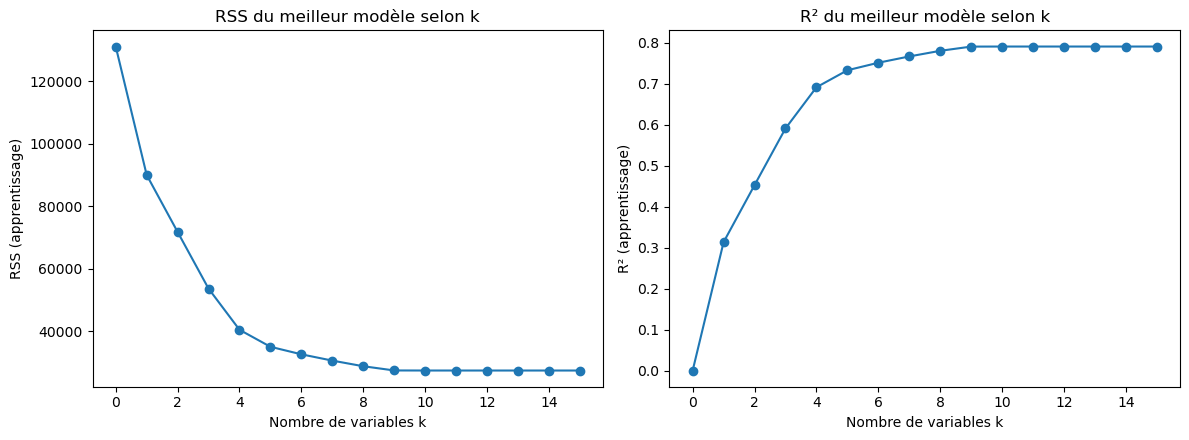

In [9]:
# Question 3.3 :

best_subset["R2"] = 1 - best_subset["RSS"] / best_subset.loc[0, "RSS"]  # On calcule le R² de chaque meilleur modèle.

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))  # On crée deux graphiques côte à côte.

axes[0].plot(best_subset.index, best_subset["RSS"], marker="o")  # On trace la RSS selon k.
axes[0].set_xlabel("Nombre de variables k")  # On nomme l'axe horizontal.
axes[0].set_ylabel("RSS (apprentissage)")  # On nomme l'axe vertical.
axes[0].set_title("RSS du meilleur modèle selon k")  # On ajoute le titre.

axes[1].plot(best_subset.index, best_subset["R2"], marker="o")  # On trace le R² selon k.
axes[1].set_xlabel("Nombre de variables k")  # On nomme l'axe horizontal.
axes[1].set_ylabel("R² (apprentissage)")  # On nomme l'axe vertical.
axes[1].set_title("R² du meilleur modèle selon k")  # On ajoute le titre.

plt.tight_layout()  # On ajuste les marges.
plt.show()  # On affiche la figure.

La RSS diminue à chaque variable ajoutée, et le R² augmente. La baisse est forte jusqu'à k = 9 (R² = 0,79), puis la courbe devient plate : les 6 dernières variables n'apportent presque rien.

Ce critère ne permet pas de choisir k, car la RSS d'apprentissage baisse toujours quand on ajoute une variable, même inutile. Si on choisissait le k qui minimise la RSS, on prendrait toujours le modèle complet (k = 15).

La RSS mesure l'ajustement aux données d'apprentissage, pas la qualité de prédiction sur de nouvelles données. Il faut donc un critère qui pénalise le nombre de variables (AIC, BIC, R² ajusté) ou qui estime l'erreur de prédiction (validation croisée).

           AIC         BIC  R2_ajuste  RMSE_CV
k                                             
0   25311.7347  25318.0287     0.0000   5.7267
1   23810.4164  23823.0045     0.3131   4.7476
2   22907.6682  22926.5503     0.4520   4.2402
3   21745.9602  21771.1364     0.5902   3.6660
4   20623.0627  20654.5330     0.6906   3.1862
5   20048.6895  20086.4538     0.7321   2.9661
6   19766.3527  19810.4111     0.7504   2.8625
7   19514.1055  19564.4579     0.7657   2.7756
8   19274.2540  19330.9004     0.7794   2.6926
9   19084.8726  19147.8131     0.7896   2.6300
10  19084.0260  19153.2605     0.7897   2.6309
11  19085.8504  19161.3790     0.7897   2.6320
12  19087.8146  19169.6373     0.7896   2.6325
13  19089.7915  19177.9082     0.7896   2.6328
14  19091.7719  19186.1827     0.7895   2.6331
15  19093.7652  19194.4700     0.7895   2.6349
Taille optimale selon chaque critère : {'AIC': np.int64(10), 'BIC': np.int64(9), 'R2_ajuste': np.int64(10), 'RMSE_CV': np.int64(9)}


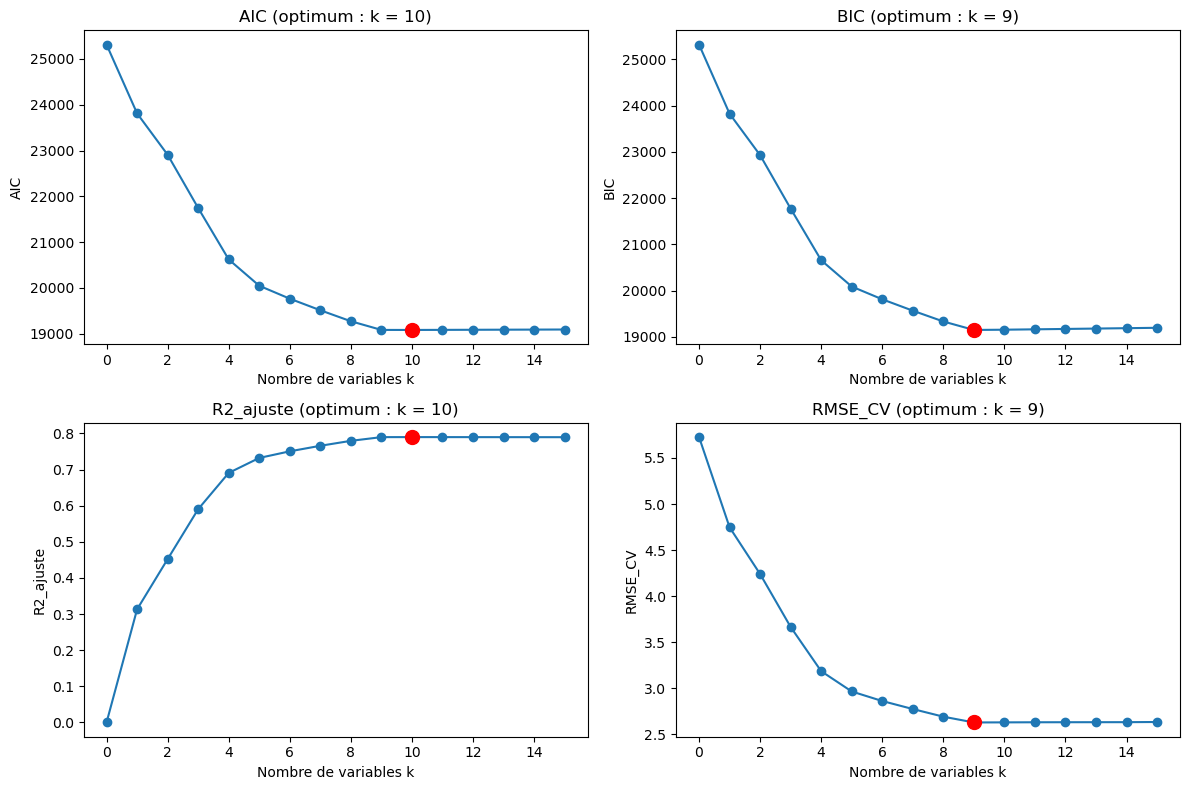

['surface_habitable_m2', 'qualite_quartier_indice', 'revenu_median_quartier_keur', 'distance_centre_ville_km', 'taux_criminalite_quartier', 'note_ecoles_proximite', 'anciennete_bien_annees', 'taux_chomage_local', 'isolation_energetique_dpe']


In [11]:
# Question 3.4 :

from sklearn.model_selection import KFold, cross_val_score  # On importe les outils de validation croisée.

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # On définit les 5 plis.

criteres = []  # On prépare la liste des résultats.
for k, liste in best_subset["variables"].items():  # On parcourt les 16 meilleurs modèles.
    X_k = X_train_const[["const"] + liste]  # On sélectionne la constante et les variables du modèle.
    modele = sm.OLS(y_train, X_k).fit()  # On ajuste le modèle.
    scores = cross_val_score(LinearRegression(), X_k, y_train, cv=cv, scoring="neg_mean_squared_error")  # On calcule la MSE sur les 5 plis.
    criteres.append({"k": k, "AIC": modele.aic, "BIC": modele.bic, "R2_ajuste": modele.rsquared_adj, "RMSE_CV": np.sqrt(-scores.mean())})  # On enregistre les quatre critères.

criteres = pd.DataFrame(criteres).set_index("k")  # On range les critères dans un tableau.
print(criteres.round(4))  # On affiche le tableau.

optimum = {"AIC": criteres["AIC"].idxmin(), "BIC": criteres["BIC"].idxmin(), "R2_ajuste": criteres["R2_ajuste"].idxmax(), "RMSE_CV": criteres["RMSE_CV"].idxmin()}  # On repère la meilleure taille par critère.
print("Taille optimale selon chaque critère :", optimum)  # On affiche les tailles optimales.

fig, axes = plt.subplots(2, 2, figsize=(12, 8))  # On crée une grille de quatre graphiques.
for ax, nom in zip(axes.ravel(), criteres.columns):  # On parcourt les quatre critères.
    ax.plot(criteres.index, criteres[nom], marker="o")  # On trace le critère selon k.
    ax.plot(optimum[nom], criteres.loc[optimum[nom], nom], "or", markersize=10)  # On marque l'optimum en rouge.
    ax.set_xlabel("Nombre de variables k")  # On nomme l'axe horizontal.
    ax.set_ylabel(nom)  # On nomme l'axe vertical.
    ax.set_title(f"{nom} (optimum : k = {optimum[nom]})")  # On ajoute le titre.
plt.tight_layout()  # On ajuste les marges.
plt.show()  # On affiche la figure.

variables_best_subset = best_subset.loc[9, "variables"]  # On retient le modèle à 9 variables.
print(variables_best_subset)  # On affiche les variables retenues.

Les critères ne s'accordent pas exactement, mais ils sont très proches :

* Le BIC et la RMSE de validation croisée choisissent k = 9.
* L'AIC et le R² ajusté choisissent k = 10.

La 10ᵉ variable est indice_pollution_air. Son apport est négligeable : l'AIC ne baisse que de 0,8 point et le R² ajusté ne gagne que 0,0001, alors que la RMSE de validation croisée augmente légèrement (2,6300 à 2,6309). L'AIC et le R² ajusté pénalisent moins le nombre de variables que le BIC, ils ont donc tendance à garder une variable de trop.

Choix final. On retient le modèle à 9 variables, selon le BIC, confirmé par la validation croisée qui estime directement l'erreur de prédiction. À performance égale, on préfère le modèle le plus simple.

Les 9 variables retenues sont : surface_habitable_m2, qualite_quartier_indice, revenu_median_quartier_keur, distance_centre_ville_km, taux_criminalite_quartier, note_ecoles_proximite, anciennete_bien_annees, taux_chomage_local et isolation_energetique_dpe.

Le modèle ne garde qu'une variable du groupe « taille » (surface_habitable_m2) et écarte parkings et ascenseur.

## Partie 4 : Forward Selection

**Question 4.1 :**

Principe. On part du modèle avec la constante seule (M₀). À chaque étape, on ajoute la variable qui améliore le plus le modèle, parmi celles qui restent, jusqu'à obtenir le modèle complet. On choisit ensuite le meilleur modèle parmi M₀, M₁, …, Mₚ avec un critère (AIC, BIC, validation croisée). Une variable entrée ne ressort plus.

Nombre de modèles. Dans le pire des cas : 1 + p + (p − 1) + … + 1 = 1 + p(p + 1)/2.

Comparaison. Pour p = 25, cela fait 326 modèles, contre 2²⁵ = 33 554 432 pour la sélection exhaustive. Le coût est quadratique au lieu d'exponentiel, mais la méthode ne garantit pas de trouver le meilleur sous-ensemble.

In [12]:
# Question 4.2 : 

def rmse_cv(liste):  # On définit la RMSE de validation croisée d'un sous-ensemble.
    scores = cross_val_score(LinearRegression(), X_train_const[["const"] + liste], y_train, cv=cv, scoring="neg_mean_squared_error")  # On calcule la MSE sur les 5 plis.
    return np.sqrt(-scores.mean())  # On renvoie la RMSE moyenne.

selection = []  # On part d'un modèle sans variable.
restantes = list(variables)  # On liste les 25 variables candidates.
meilleure_rmse = rmse_cv(selection)  # On calcule la RMSE de la constante seule.
etapes = [{"étape": 0, "variable ajoutée": "(constante seule)", "RMSE_CV": meilleure_rmse}]  # On enregistre l'étape initiale.

while restantes:  # On continue tant qu'il reste des variables.
    essais = {v: rmse_cv(selection + [v]) for v in restantes}  # On teste l'ajout de chaque variable restante.
    candidate = min(essais, key=essais.get)  # On repère la variable qui donne la plus petite RMSE.
    if essais[candidate] >= meilleure_rmse:  # On vérifie si la RMSE s'améliore.
        print(f"Arrêt : ajouter {candidate} donnerait une RMSE(CV) de {essais[candidate]:.4f}, sans amélioration.")  # On affiche la raison de l'arrêt.
        break  # On arrête la sélection.
    selection.append(candidate)  # On ajoute la variable au modèle.
    restantes.remove(candidate)  # On retire la variable des candidates.
    meilleure_rmse = essais[candidate]  # On met à jour la meilleure RMSE.
    etapes.append({"étape": len(selection), "variable ajoutée": candidate, "RMSE_CV": meilleure_rmse})  # On enregistre l'étape.

variables_forward = selection  # On conserve les variables retenues.
etapes_forward = pd.DataFrame(etapes).set_index("étape")  # On range les étapes dans un tableau.
etapes_forward.round(4)  # On affiche les étapes.

Arrêt : ajouter presence_jardin_score donnerait une RMSE(CV) de 2.6296, sans amélioration.


,variable ajoutée,RMSE_CV
étape,,
0,(constante seule),5.7267
1,surface_habitable_m2,4.7476
2,qualite_quartier_indice,4.2402
3,distance_centre_ville_km,3.6660
4,taux_criminalite_quartier,3.1862
5,note_ecoles_proximite,2.9661
6,anciennete_bien_annees,2.8625
7,revenu_median_quartier_keur,2.7756
8,isolation_energetique_dpe,2.6926


À chaque étape, on ajoute la variable qui donne la plus petite RMSE en validation croisée à 5 plis. On s'arrête dès que le meilleur ajout possible ne fait plus baisser la RMSE.

La sélection ascendante retient 11 variables, avec une RMSE(CV) finale de 2,6294. Les 9 premières variables font baisser la RMSE nettement, de 5,73 à 2,63. Les deux dernières (exposition_soleil_score et distance_commerces_km) n'apportent qu'un gain de 0,0006 au total. L'algorithme s'arrête à l'étape 12, car l'ajout de presence_jardin_score ferait remonter la RMSE.

In [13]:
# Question 4.3 : 

communes = [v for v in variables_forward if v in variables_best_subset]  # On liste les variables communes.
seulement_forward = [v for v in variables_forward if v not in variables_best_subset]  # On liste les variables propres au forward.
seulement_best = [v for v in variables_best_subset if v not in variables_forward]  # On liste les variables propres au best subset.

print("Variables communes :", len(communes))  # On affiche le nombre de variables communes.
print("Seulement dans le forward :", seulement_forward)  # On affiche les ajouts du forward.
print("Seulement dans le best subset :", seulement_best)  # On affiche les ajouts du best subset.
print("Hors du pool réduit :", [v for v in seulement_forward if v not in pool])  # On vérifie si ces ajouts étaient dans le pool.

Variables communes : 9
Seulement dans le forward : ['exposition_soleil_score', 'distance_commerces_km']
Seulement dans le best subset : []
Hors du pool réduit : ['exposition_soleil_score', 'distance_commerces_km']


Oui, les deux méthodes convergent. Les 9 variables retenues par la sélection exhaustive sont toutes retenues par la sélection ascendante, et elles entrent dans le même ordre.

La seule différence est que la sélection ascendante ajoute deux variables : exposition_soleil_score et distance_commerces_km. Deux raisons l'expliquent :

Les candidates ne sont pas les mêmes. Ces deux variables ne font pas partie du pool réduit de 15 variables : la sélection exhaustive ne pouvait donc pas les choisir.
Le critère d'arrêt est moins strict. La sélection ascendante garde toute variable qui fait baisser la RMSE(CV), même très peu. Ici le gain total est de 0,0006 (2,6300 à 2,6294), ce qui est négligeable. Le BIC, utilisé en Partie 3, pénalise davantage le nombre de variables.

Ces deux variables supplémentaires sont donc probablement du bruit : le modèle à 9 variables prédit aussi bien et reste plus simple.

## Partie 5 : Backward Selection 

**Question 5.1 :** Principe. On part du modèle complet avec les p variables. À chaque étape, on retire la variable la moins utile, jusqu’au modèle avec la constante seule. On choisit ensuite le meilleur modèle parmi M₀, …, Mₚ avec un critère. Une variable retirée ne revient plus.

Cas où elle ne s’applique pas. Quand p ≥ n, le modèle complet ne peut pas être ajusté par moindres carrés (pas de solution unique). La sélection ascendante reste possible, car elle part du modèle vide.

Dans notre cas. Non : n = 4 000 et p = 25, donc n est très supérieur à p. La sélection descendante est applicable.

In [14]:
# Question 5.2 :

selection = list(variables)  # On part du modèle complet à 25 variables.
meilleure_rmse = rmse_cv(selection)  # On calcule la RMSE du modèle complet.
etapes = [{"étape": 0, "variable retirée": "(modèle complet)", "nb_variables": len(selection), "RMSE_CV": meilleure_rmse}]  # On enregistre l'étape initiale.

while selection:  # On continue tant qu'il reste des variables.
    essais = {v: rmse_cv([w for w in selection if w != v]) for v in selection}  # On teste le retrait de chaque variable.
    candidate = min(essais, key=essais.get)  # On repère le retrait qui donne la plus petite RMSE.
    if essais[candidate] >= meilleure_rmse:  # On vérifie si la RMSE s'améliore.
        print(f"Arrêt : retirer {candidate} donnerait une RMSE(CV) de {essais[candidate]:.4f}, sans amélioration.")  # On affiche la raison de l'arrêt.
        break  # On arrête la sélection.
    selection.remove(candidate)  # On retire la variable du modèle.
    meilleure_rmse = essais[candidate]  # On met à jour la meilleure RMSE.
    etapes.append({"étape": len(etapes), "variable retirée": candidate, "nb_variables": len(selection), "RMSE_CV": meilleure_rmse})  # On enregistre l'étape.

variables_backward = selection  # On conserve les variables retenues.
etapes_backward = pd.DataFrame(etapes).set_index("étape")  # On range les étapes dans un tableau.
print("Variables retenues :", variables_backward)  # On affiche les variables retenues.
etapes_backward.round(4)  # On affiche les étapes.

Arrêt : retirer distance_commerces_km donnerait une RMSE(CV) de 2.6295, sans amélioration.
Variables retenues : ['surface_habitable_m2', 'qualite_quartier_indice', 'revenu_median_quartier_keur', 'distance_centre_ville_km', 'taux_criminalite_quartier', 'note_ecoles_proximite', 'anciennete_bien_annees', 'taux_chomage_local', 'isolation_energetique_dpe', 'exposition_soleil_score', 'distance_commerces_km']


,variable retirée,nb_variables,RMSE_CV
étape,,,
0,(modèle complet),25,2.6415
1,age_moyen_habitants_quartier,24,2.6397
2,nombre_chambres,23,2.6379
3,taux_natalite_quartier,22,2.6362
4,type_chauffage_score,21,2.6349
5,indice_pollution_air,20,2.6340
6,nombre_pieces,19,2.6331
7,bruit_route_score,18,2.6324
8,nombre_habitants_quartier_milliers,17,2.6318


On part du modèle complet (RMSE(CV) = 2,6415). À chaque étape, on retire la variable dont la suppression donne la plus petite RMSE(CV), et on s’arrête quand aucun retrait ne l’améliore.

La sélection descendante retire 14 variables et en retient 11, avec une RMSE(CV) finale de 2,6294. Chaque retrait améliore légèrement la RMSE : les variables supprimées n’apportaient que du bruit. Parmi elles figurent les trois variables redondantes du groupe « taille » (nombre_chambres, nombre_pieces, surface_terrain_m2), ainsi que parkings et ascenseur.

In [15]:
# Question 5.3 : 

print("Même sous-ensemble :", set(variables_forward) == set(variables_backward))  # On compare les deux sous-ensembles.
print("Nombre de variables :", len(variables_forward), "(forward) et", len(variables_backward), "(backward)")  # On affiche les tailles.
print("RMSE(CV) :", round(rmse_cv(variables_forward), 4), "(forward) et", round(rmse_cv(variables_backward), 4), "(backward)")  # On affiche les RMSE.

Même sous-ensemble : True
Nombre de variables : 11 (forward) et 11 (backward)
RMSE(CV) : 2.6294 (forward) et 2.6294 (backward)


Oui, les deux méthodes donnent exactement le même sous-ensemble de 11 variables, avec la même RMSE(CV) de 2,6294. Ici le signal est net : 9 variables ont un effet fort, les autres presque aucun, et l’échantillon est grand. Les deux chemins arrivent donc au même endroit.

Ce résultat n’est pas garanti. Les deux heuristiques peuvent diverger pour trois raisons :

* Elles partent de points opposés et leurs choix sont irréversibles. Le forward ne retire jamais une variable entrée, le backward ne réintègre jamais une variable retirée. Une erreur faite tôt n’est jamais corrigée.
* Elles n’explorent qu’une petite partie des modèles. Chacune suit un seul chemin d’environ p(p + 1)/2 modèles parmi 2ᵖ, et s’arrête à la première étape sans amélioration. Elles peuvent donc aboutir à deux optimums locaux différents.
* Elles évaluent une variable dans des contextes différents. Le forward juge une variable avec peu d’autres variables dans le modèle, le backward la juge en présence de toutes les autres. Avec des variables corrélées, l’utilité d’une variable dépend de celles déjà présentes : les deux méthodes peuvent alors garder des variables différentes d’un même groupe.

## Partie 6 Régression Ridge et validation croisée 

**Q6.1** — **Fonction objectif.** La régression Ridge choisit les coefficients qui minimisent la RSS augmentée d'une pénalité sur la taille des coefficients :

$$\hat{\beta}^{ridge} = \arg\min_{\beta} \; \sum_{i=1}^{n}\left(Y_i-(\beta_0+\beta_1X_{1i}+\dots+\beta_pX_{pi})\right)^2+\lambda\sum_{j=1}^{p}\beta_j^2$$

où $\lambda \geq 0$ est le paramètre de régularisation (noté $\alpha$ dans le sujet et dans scikit-learn). La constante $\beta_0$ n'est pas pénalisée. Si $\lambda = 0$, on retrouve les moindres carrés ordinaires : $\hat{\beta}^{ridge} = \hat{\beta}^{OLS}$.

**Effet sur la colinéarité.** Avec des variables très corrélées, la matrice $X^TX$ est presque non inversible : les coefficients des moindres carrés sont instables et leur variance est gonflée ($VIF \approx 5$ pour le groupe « taille » en Partie 2). La solution Ridge s'écrit

$$\hat{\beta}^{ridge} = (X^TX + \lambda I_p)^{-1}X^TY$$

et la matrice $X^TX + \lambda I_p$ est toujours inversible dès que $\lambda > 0$. La pénalité empêche les coefficients de prendre de trop grandes valeurs : quand $\lambda$ augmente, le biais augmente mais la variance diminue. Les variables corrélées se partagent alors l'effet avec des coefficients stables.

**Pas de sélection.** La pénalité $\ell_2$ rétrécit les coefficients vers 0 sans jamais les annuler exactement. Ridge conserve donc les 25 variables : il stabilise le modèle, mais il ne choisit pas de sous-ensemble.

Alpha optimal (Ridge) : 2.6827
RMSE(CV) minimale : 2.6415


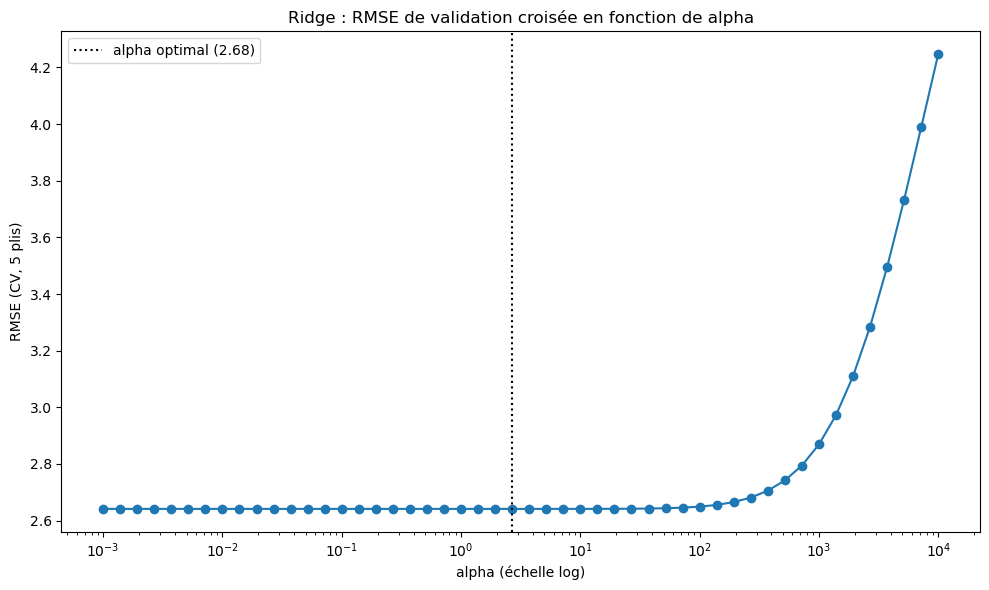

In [16]:
# Question 6.2 : 

from sklearn.linear_model import Ridge  # On importe la régression Ridge.
from sklearn.model_selection import GridSearchCV  # On importe la recherche sur grille.
from sklearn.preprocessing import StandardScaler  # On importe la standardisation.
from sklearn.pipeline import Pipeline  # On importe le pipeline.

ridge_pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge())])  # On enchaîne standardisation et Ridge.
alphas_ridge = np.logspace(-3, 4, 50)  # On définit la grille de 50 valeurs de alpha.

gs_ridge = GridSearchCV(ridge_pipe, {"model__alpha": alphas_ridge}, cv=cv, scoring="neg_mean_squared_error")  # On prépare la validation croisée à 5 plis.
gs_ridge.fit(X_train, y_train)  # On teste chaque alpha sur l'apprentissage.

best_ridge = gs_ridge.best_estimator_  # On récupère le meilleur modèle Ridge.
alpha_ridge_opt = gs_ridge.best_params_["model__alpha"]  # On récupère le alpha optimal.
rmse_ridge_grille = np.sqrt(-gs_ridge.cv_results_["mean_test_score"])  # On calcule la RMSE(CV) de chaque alpha.
rmse_ridge_cv = np.sqrt(-gs_ridge.best_score_)  # On calcule la RMSE(CV) minimale.

print(f"Alpha optimal (Ridge) : {alpha_ridge_opt:.4f}")  # On affiche le alpha optimal.
print(f"RMSE(CV) minimale : {rmse_ridge_cv:.4f}")  # On affiche la RMSE minimale.

plt.figure(figsize=(10, 6))  # On fixe la taille de la figure.
plt.plot(alphas_ridge, rmse_ridge_grille, marker="o")  # On trace la RMSE(CV) selon alpha.
plt.axvline(alpha_ridge_opt, color="black", linestyle=":", label=f"alpha optimal ({alpha_ridge_opt:.2f})")  # On marque le alpha optimal.
plt.xscale("log")  # On passe l'axe horizontal en échelle log.
plt.xlabel("alpha (échelle log)")  # On nomme l'axe horizontal.
plt.ylabel("RMSE (CV, 5 plis)")  # On nomme l'axe vertical.
plt.title("Ridge : RMSE de validation croisée en fonction de alpha")  # On ajoute le titre.
plt.legend()  # On affiche la légende.
plt.tight_layout()  # On ajuste les marges.
plt.show()  # On affiche la figure.

La validation croisée à 5 plis donne un paramètre optimal $\alpha \approx 2{,}68$, avec une RMSE(CV) de 2,6415

La courbe est presque plate tant que $\alpha < 10$ : la RMSE(CV) reste à $2{,}6415$, soit la même valeur que le modèle complet sans pénalité (Q5.2). Elle augmente ensuite fortement quand $\alpha$ dépasse 100, car une pénalité trop forte écrase les coefficients et crée du biais (sous-apprentissage).

Ridge n'améliore donc presque pas la prédiction ici. C'est logique : avec $n = 4\,000$ observations pour $p = 25$ variables, les moindres carrés sont déjà stables, et la colinéarité reste modérée ($VIF \approx 5$). L'optimum est peu marqué, toute valeur de $\alpha$ entre $0{,}001$ et $10$ donne pratiquement la même erreur.

Les données étant déjà centrées-réduites, le `StandardScaler` du pipeline ne change presque rien : on le garde pour que la standardisation soit refaite sur chaque pli d'apprentissage, sans fuite d'information.

**Question 6.3** — **Rappel.** En validation croisée à $k$ plis, chaque modèle est ajusté sur $n\,\frac{k-1}{k}$ observations et évalué sur les $\frac{n}{k}$ restantes. L'erreur estimée est la moyenne des $k$ erreurs :

$$CV_{(k)} = \frac{1}{k}\sum_{j=1}^{k} MSE_j$$

**Effet de $k$ sur le biais.** Les modèles sont ajustés sur moins de $n$ observations : ils sont un peu moins bons que le modèle final, donc l'erreur est surestimée (biais pessimiste). Plus $k$ est grand, plus les échantillons d'apprentissage sont proches de $n$, et plus ce biais diminue.

**Effet de $k$ sur la variance.** Plus $k$ est grand, plus les échantillons d'apprentissage se recouvrent. Les $k$ modèles se ressemblent, leurs erreurs sont très corrélées, et la moyenne de termes corrélés a une variance plus élevée. Le coût de calcul augmente aussi, puisqu'il faut $k$ ajustements.

**Cas $k = 2$.** Chaque modèle n'utilise que $\frac{n}{2}$ observations : la moitié des données est « gaspillée ». Le biais est fort, l'erreur est nettement surestimée, et le résultat dépend beaucoup du découpage. En contrepartie, le calcul est très rapide (2 ajustements).

**Cas $k = n$ (leave-one-out).** Chaque modèle utilise $n - 1$ observations : le biais est quasi nul. Mais les $n$ modèles sont presque identiques, donc leurs erreurs sont très corrélées et la variance de l'estimation est élevée. Le coût est maximal ($n$ ajustements).

**Conclusion.** Quand $k$ augmente, le biais diminue et la variance augmente. On choisit en pratique $k = 5$ ou $k = 10$, qui donnent un bon compromis pour un coût raisonnable. Ici, avec $k = 5$ et $n = 4\,000$, chaque modèle est ajusté sur $3\,200$ observations et évalué sur $800$.

## Partie 7 : Régression Lasso

**Question 7.1** — **Formulation contrainte.** Ridge et Lasso reviennent tous deux à minimiser la RSS sous une contrainte sur la taille des coefficients. Avec deux coefficients :

$$\text{Ridge} : \; \min_{\beta} RSS(\beta) \quad \text{sous contrainte} \quad \beta_1^2 + \beta_2^2 \leq s$$

$$\text{Lasso} : \; \min_{\beta} RSS(\beta) \quad \text{sous contrainte} \quad |\beta_1| + |\beta_2| \leq s$$

Un $s$ petit correspond à un $\lambda$ grand, donc à une forte régularisation.

**Différence géométrique.** Les courbes de niveau de la RSS sont des ellipses centrées sur l'estimateur des moindres carrés $\hat{\beta}^{OLS}$. La solution est le premier point de contact entre ces ellipses et la région de contrainte. Cette région n'a pas la même forme :
- Pour Ridge, c'est un **disque** (boule $\ell_2$), dont la frontière est lisse partout.
- Pour le Lasso, c'est un **losange** (boule $\ell_1$), qui possède des **coins situés sur les axes**.

**Conséquence.** Sur un axe, l'un des deux coefficients vaut exactement 0.
- Le losange présente des coins qui « dépassent » : les ellipses le touchent souvent en un coin, donc avec $\hat{\beta}_1 = 0$ ou $\hat{\beta}_2 = 0$. Le Lasso annule alors exactement un coefficient : il fait de la sélection de variables.
- Le disque n'a aucun point privilégié : le contact a lieu en général à l'intérieur d'un quadrant, avec $\hat{\beta}_1 \neq 0$ et $\hat{\beta}_2 \neq 0$. Ridge rétrécit les coefficients sans les annuler.

On peut le voir aussi par le gradient : celui de la pénalité $\ell_2$, $\lambda \beta_j^2$, s'annule en $\beta_j = 0$, donc rien ne « pousse » le coefficient jusqu'à zéro. La pénalité $\ell_1$, $\lambda |\beta_j|$, garde une pente constante $\lambda$ jusqu'en 0.

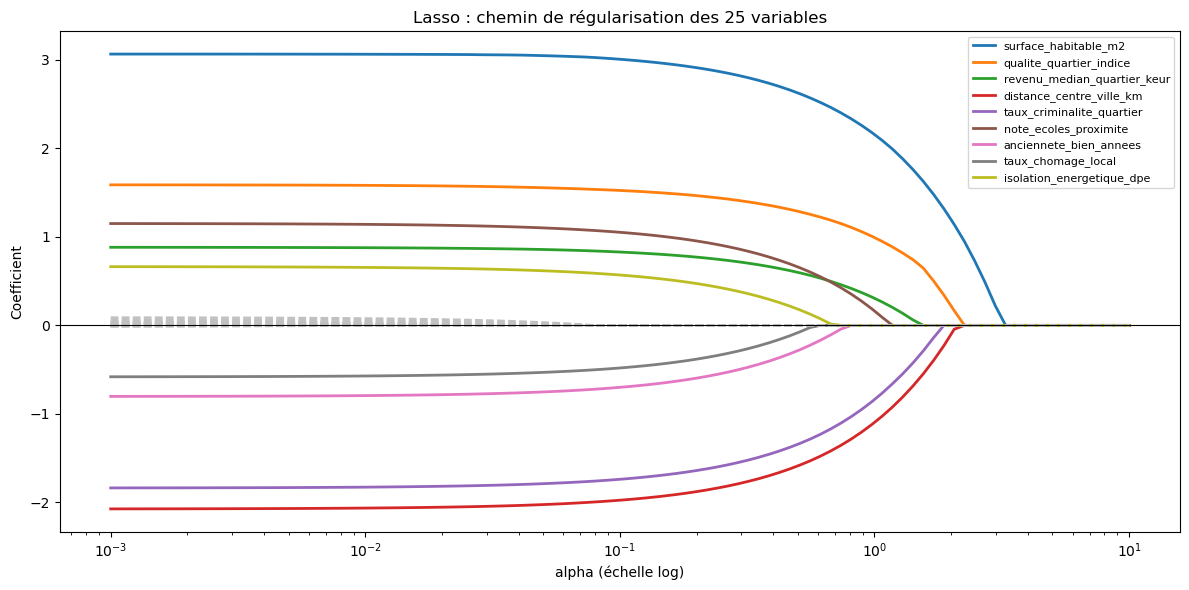

In [19]:
# Question 7.2 :

from sklearn.linear_model import Lasso  # On importe la régression Lasso.

alphas_lasso = np.logspace(-3, 1, 100)  # On définit la grille de 100 valeurs de alpha.

coefs_lasso_path = []  # On prépare la liste des coefficients.
for a in alphas_lasso:  # On parcourt les valeurs de alpha.
    p = Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=a, max_iter=10000))])  # On enchaîne standardisation et Lasso.
    p.fit(X_train, y_train)  # On ajuste le modèle sur l'apprentissage.
    coefs_lasso_path.append(p.named_steps["model"].coef_)  # On enregistre les 25 coefficients.
coefs_lasso_path = np.array(coefs_lasso_path)  # On convertit la liste en tableau.

plt.figure(figsize=(12, 6))  # On fixe la taille de la figure.
for j, nom in enumerate(variables):  # On parcourt les 25 variables.
    if np.abs(coefs_lasso_path[:, j]).max() > 0.3:  # On repère les variables à fort coefficient.
        plt.plot(alphas_lasso, coefs_lasso_path[:, j], linewidth=2, label=nom)  # On trace la variable en couleur.
    else:  # On traite les autres variables.
        plt.plot(alphas_lasso, coefs_lasso_path[:, j], color="silver", linestyle="--")  # On trace la variable en gris.
plt.axhline(0, color="black", linewidth=0.8)  # On trace la ligne du zéro.
plt.xscale("log")  # On passe l'axe horizontal en échelle log.
plt.xlabel("alpha (échelle log)")  # On nomme l'axe horizontal.
plt.ylabel("Coefficient")  # On nomme l'axe vertical.
plt.title("Lasso : chemin de régularisation des 25 variables")  # On ajoute le titre.
plt.legend(loc="upper right", fontsize=8)  # On affiche la légende.
plt.tight_layout()  # On ajuste les marges.
plt.show()  # On affiche la figure.

Le chemin de régularisation montre l'évolution des 25 coefficients quand la pénalité $\alpha$ augmente.

- Pour $\alpha$ très petit ($\alpha = 0{,}001$), les 25 coefficients sont non nuls et proches de ceux des moindres carrés.
- Les 16 variables peu utiles (en gris) ont des coefficients très faibles dès le départ (inférieurs à $0{,}1$ en valeur absolue). Elles sont toutes annulées dès que $\alpha$ dépasse environ $0{,}08$.
- Les 9 variables principales (en couleur) résistent beaucoup plus longtemps. Entre $\alpha \approx 0{,}08$ et $\alpha \approx 0{,}56$, le modèle contient exactement ces 9 variables.
- Pour $\alpha$ grand, elles sont annulées à leur tour, de la moins importante (`taux_chomage_local`) à la plus importante (`surface_habitable_m2`, annulée vers $\alpha \approx 3$). Au-delà, tous les coefficients valent 0.

Contrairement à Ridge, les coefficients atteignent **exactement** zéro : le Lasso fait de la sélection de variables. L'ordre dans lequel les variables disparaissent donne aussi un classement de leur importance.

In [21]:
# Question 7.3 :

lasso_pipe = Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=10000))])  # On enchaîne standardisation et Lasso.

gs_lasso = GridSearchCV(lasso_pipe, {"model__alpha": alphas_lasso}, cv=cv, scoring="neg_mean_squared_error")  # On prépare la validation croisée à 5 plis.
gs_lasso.fit(X_train, y_train)  # On teste chaque alpha sur l'apprentissage.

best_lasso = gs_lasso.best_estimator_  # On récupère le meilleur modèle Lasso.
alpha_lasso_opt = gs_lasso.best_params_["model__alpha"]  # On récupère le alpha optimal.
rmse_lasso_cv = np.sqrt(-gs_lasso.best_score_)  # On calcule la RMSE(CV) minimale.

coef_lasso = pd.Series(best_lasso.named_steps["model"].coef_, index=variables)  # On range les coefficients par variable.
variables_lasso = coef_lasso[coef_lasso != 0].index.tolist()  # On liste les variables retenues.
variables_annulees = coef_lasso[coef_lasso == 0].index.tolist()  # On liste les variables éliminées.

print(f"Alpha optimal (Lasso) : {alpha_lasso_opt:.4f}")  # On affiche le alpha optimal.
print(f"RMSE(CV) minimale : {rmse_lasso_cv:.4f}")  # On affiche la RMSE minimale.
print(f"Variables retenues ({len(variables_lasso)}) :")  # On affiche le nombre de variables retenues.
print(coef_lasso[variables_lasso].round(4))  # On affiche leurs coefficients.
print(f"Variables éliminées ({len(variables_annulees)}) : {variables_annulees}")  # On affiche les variables éliminées.

Alpha optimal (Lasso) : 0.0343
RMSE(CV) minimale : 2.6366
Variables retenues (15) :
surface_habitable_m2           3.0568
nombre_pieces                  0.0070
surface_terrain_m2             0.0098
qualite_quartier_indice        1.5661
revenu_median_quartier_keur    0.8655
distance_centre_ville_km      -2.0407
taux_criminalite_quartier     -1.8042
note_ecoles_proximite          1.1174
anciennete_bien_annees        -0.7682
taux_chomage_local            -0.5469
isolation_energetique_dpe      0.6323
type_chauffage_score           0.0090
exposition_soleil_score        0.0530
distance_commerces_km          0.0191
indice_pollution_air           0.0359
dtype: float64
Variables éliminées (10) : ['nombre_chambres', 'nombre_parkings', 'presence_ascenseur', 'bruit_route_score', 'presence_jardin_score', 'distance_ecole_primaire_km', 'taux_natalite_quartier', 'nombre_habitants_quartier_milliers', 'age_moyen_habitants_quartier', 'taux_proprietaires_quartier']


La validation croisée à 5 plis donne $\alpha \approx 0{,}034$, avec une RMSE(CV) de $2{,}6366$.

Le Lasso retient **15 variables** et en élimine **10** (coefficient exactement nul).

Parmi les 15 variables retenues, on distingue deux groupes :
- 9 variables à fort coefficient (entre $0{,}55$ et $3{,}06$ en valeur absolue) : ce sont exactement les 9 variables du best subset.
- 6 variables à coefficient très faible (inférieur à $0{,}06$) : `nombre_pieces`, `surface_terrain_m2`, `type_chauffage_score`, `exposition_soleil_score`, `distance_commerces_km` et `indice_pollution_air`. Elles sont conservées, mais leur effet est négligeable.

Le Lasso retient donc plus de variables que les méthodes précédentes (9 pour le best subset, 11 pour le forward et le backward). C'est attendu : le $\alpha$ qui minimise l'erreur de prédiction est assez petit, et il laisse passer quelques variables de bruit avec un coefficient proche de 0.

In [22]:
# Question 7.4 :

groupes = {"Taille du bien": ["surface_habitable_m2", "nombre_pieces", "surface_terrain_m2", "nombre_chambres"],
           "Équipements": ["nombre_parkings", "presence_ascenseur"],
           "Quartier": ["qualite_quartier_indice", "revenu_median_quartier_keur"]}  # On reprend les trois groupes corrélés de la Q1.2.

for nom, liste in groupes.items():  # On parcourt les trois groupes.
    print(nom)  # On affiche le nom du groupe.
    print(coef_lasso[liste].round(4), "\n")  # On affiche les coefficients Lasso du groupe.

Taille du bien
surface_habitable_m2    3.0568
nombre_pieces           0.0070
surface_terrain_m2      0.0098
nombre_chambres         0.0000
dtype: float64 

Équipements
nombre_parkings      -0.0
presence_ascenseur    0.0
dtype: float64 

Quartier
qualite_quartier_indice        1.5661
revenu_median_quartier_keur    0.8655
dtype: float64 



**En théorie.** Face à un groupe de variables fortement corrélées, le Lasso a tendance à n'en garder qu'une et à annuler les autres. Ces variables portent la même information : en garder une seule coûte moins cher en pénalité $\ell_1$ que de répartir l'effet sur plusieurs. Le choix de la variable conservée est assez arbitraire et peut changer avec l'échantillon.

**Vérification sur nos trois groupes.**
- **Taille du bien** ($r \approx 0{,}85$) : le Lasso concentre presque tout l'effet sur `surface_habitable_m2` ($3{,}06$). `nombre_chambres` est annulée, `nombre_pieces` et `surface_terrain_m2` ont des coefficients négligeables ($< 0{,}01$). Le comportement attendu est donc confirmé. Ici le choix n'est pas vraiment arbitraire : `surface_habitable_m2` était déjà la seule variable significative du groupe en Partie 2.
- **Équipements** ($r = 0{,}71$) : `nombre_parkings` et `presence_ascenseur` sont toutes deux annulées, car aucune n'a d'effet sur le prix.
- **Quartier** ($r = 0{,}61$) : `qualite_quartier_indice` ($1{,}57$) et `revenu_median_quartier_keur` ($0{,}87$) sont toutes deux conservées. La corrélation est plus modérée et chacune apporte une information propre.

Le Lasso ne garde donc une seule variable par groupe que lorsque les variables sont réellement redondantes.

**Intérêt de l'Elastic Net.** L'Elastic Net combine les deux pénalités :

$$\sum_{i=1}^{n}\left(Y_i-(\beta_0+\beta_1X_{1i}+\dots+\beta_pX_{pi})\right)^2+\lambda\left(\alpha\sum_{j=1}^{p}|\beta_j|+(1-\alpha)\sum_{j=1}^{p}\beta_j^2\right)$$

avec $\alpha = 1$ pour le Lasso et $\alpha = 0$ pour Ridge. La partie $\ell_1$ conserve la sélection de variables. La partie $\ell_2$ répartit l'effet entre les variables corrélées, qui entrent ou sortent du modèle ensemble : la sélection devient plus stable et moins arbitraire. C'est utile quand plusieurs variables d'un groupe ont chacune un vrai effet. Ici l'intérêt est limité, puisqu'une seule variable porte le signal du groupe « taille ».

## Partie 8 : Algorithme génétique pour la sélection de variables

**Question 8.1** — **Principe général.** Un algorithme génétique fait évoluer une population de solutions candidates en imitant la sélection naturelle. À chaque génération, les meilleures solutions sont choisies comme parents, combinées entre elles, puis légèrement modifiées au hasard. On répète l'opération pendant un nombre fixé de générations et on retient la meilleure solution rencontrée. La méthode explore ainsi une partie des $2^{25}$ sous-ensembles possibles sans les tester tous.

**Codage d'un individu.** Un individu (chromosome) est un vecteur binaire de longueur $p = 25$ :

$$c = (c_1, \dots, c_{25}), \qquad c_j = \begin{cases} 1 & \text{si la variable } j \text{ est dans le modèle} \\ 0 & \text{sinon} \end{cases}$$

Chaque chromosome représente donc un sous-ensemble de variables.

**Fonction de fitness.** On utilise le BIC du modèle linéaire ajusté sur l'apprentissage avec les variables du chromosome, à minimiser :

$$BIC = n \ln\left(\frac{RSS}{n}\right) + (k+1)\ln(n) + \text{constante}$$

où $k$ est le nombre de variables sélectionnées. Trois raisons justifient ce choix :
- La RSS seule diminue toujours quand on ajoute une variable (Q3.3) : l'algorithme convergerait vers le modèle complet. Le BIC pénalise la complexité.
- Le BIC se calcule avec un seul ajustement, alors que la validation croisée en demanderait cinq. C'est important, car l'algorithme évalue plusieurs milliers de modèles.
- Sa pénalité $\ln(n)$ est plus forte que celle de l'AIC : il favorise les modèles simples, ce qui est cohérent avec le choix fait en Partie 3.

**Opérateurs choisis.**
- **Sélection par tournoi** : on tire 3 individuals au hasard et on garde celui qui a le plus petit BIC. On répète pour obtenir chaque parent. Cette méthode est simple et ne dépend que du classement des individus.
- **Croisement uniforme** : chaque gène de l'enfant est copié du parent 1 ou du parent 2 avec une probabilité de $0{,}5$. Ce croisement convient ici car l'ordre des variables dans le chromosome n'a pas de signification.
- **Mutation par inversion de bit** : chaque gène est inversé ($0 \leftrightarrow 1$) avec une probabilité $p_m = 1/25 = 0{,}04$, soit une variable modifiée en moyenne par individu. La mutation maintient la diversité et évite de rester bloqué dans un optimum local.
- **Élitisme** : le meilleur individu de chaque génération est recopié tel quel dans la suivante, pour ne jamais perdre la meilleure solution

In [23]:
# Question 8.2 :

X_arr = X_train.values  # On convertit les variables en tableau numpy.
y_arr = y_train.values  # On convertit la cible en tableau numpy.
n = len(y_arr)  # On note le nombre d'observations.

def bic(chromosome):  # On définit la fitness d'un chromosome.
    A = np.column_stack([np.ones(n), X_arr[:, chromosome == 1]])  # On assemble la constante et les variables sélectionnées.
    rss = ((y_arr - A @ np.linalg.lstsq(A, y_arr, rcond=None)[0]) ** 2).sum()  # On calcule la RSS par moindres carrés.
    return n * np.log(rss / n) + A.shape[1] * np.log(n) + n * (1 + np.log(2 * np.pi))  # On renvoie le BIC.

def algo_genetique(taille_pop=50, nb_generations=50, taux_mutation=0.04, taille_tournoi=3, graine=RANDOM_STATE):  # On définit l'algorithme génétique.
    rng = np.random.default_rng(graine)  # On initialise le générateur aléatoire.
    population = rng.integers(0, 2, size=(taille_pop, len(variables)))  # On tire la population initiale au hasard.
    historique = []  # On prépare le suivi des générations.
    for g in range(nb_generations + 1):  # On parcourt les générations.
        scores = np.array([bic(c) for c in population])  # On évalue le BIC de chaque individu.
        historique.append({"génération": g, "meilleur_BIC": scores.min(), "BIC_moyen": scores.mean()})  # On enregistre le meilleur BIC et le BIC moyen.
        if g == nb_generations:  # On vérifie si la dernière génération est atteinte.
            break  # On arrête l'évolution.
        enfants = [population[scores.argmin()].copy()]  # On conserve le meilleur individu (élitisme).
        while len(enfants) < taille_pop:  # On crée les enfants un par un.
            parents = []  # On prépare la liste des deux parents.
            for _ in range(2):  # On sélectionne deux parents.
                candidats = rng.choice(taille_pop, size=taille_tournoi, replace=False)  # On tire les candidats du tournoi.
                parents.append(population[candidats[scores[candidats].argmin()]])  # On garde le candidat au plus petit BIC.
            enfant = np.where(rng.random(len(variables)) < 0.5, parents[0], parents[1])  # On croise les parents gène par gène.
            enfant = np.where(rng.random(len(variables)) < taux_mutation, 1 - enfant, enfant)  # On inverse certains gènes au hasard.
            enfants.append(enfant)  # On ajoute l'enfant à la nouvelle génération.
        population = np.array(enfants)  # On remplace la population.
    return population[scores.argmin()], scores.min(), pd.DataFrame(historique).set_index("génération")  # On renvoie le meilleur individu, son BIC et l'historique.

debut = time.time()  # On lance le chronomètre.
meilleur, bic_ga, historique_ga = algo_genetique()  # On exécute l'algorithme génétique.
variables_ga = [v for v, c in zip(variables, meilleur) if c == 1]  # On traduit le chromosome en liste de variables.

print(f"Temps de calcul : {time.time() - debut:.1f} s")  # On affiche le temps de calcul.
print(f"Meilleur BIC : {bic_ga:.2f}")  # On affiche le meilleur BIC.
print(f"Variables retenues ({len(variables_ga)}) : {variables_ga}")  # On affiche les variables retenues.

Temps de calcul : 1.3 s
Meilleur BIC : 19147.81
Variables retenues (9) : ['surface_habitable_m2', 'qualite_quartier_indice', 'revenu_median_quartier_keur', 'distance_centre_ville_km', 'taux_criminalite_quartier', 'note_ecoles_proximite', 'anciennete_bien_annees', 'taux_chomage_local', 'isolation_energetique_dpe']


L'algorithme génétique est codé avec les choix présentés en Q8.1 : chromosome binaire de longueur 25, fitness égale au BIC (à minimiser), sélection par tournoi de taille 3, croisement uniforme, mutation par inversion de bit ($p_m = 0{,}04$) et élitisme. La population compte 50 individus et évolue pendant 50 générations.

Le BIC est calculé par

$$BIC = n \ln\left(\frac{RSS}{n}\right) + (k+1)\ln(n) + n\left(1 + \ln(2\pi)\right)$$

soit la même définition que celle de statsmodels utilisée en Q3.4, ce qui rend les valeurs directement comparables.

**Résultat.** L'algorithme retient **9 variables**, avec un BIC de $19\,147{,}81$. Ce sont exactement les 9 variables du best subset (Q3.4), et le BIC est identique. L'algorithme a évalué au plus $51 \times 50 = 2\,550$ modèles, contre $2^{25} \approx 33{,}5$ millions pour une recherche exhaustive sur les 25 variables.

In [27]:
graines = range(5)  # On fixe les 5 graines aléatoires.

def resumer(nom, valeur, bics):  # On définit le résumé d'une configuration.
    return {"hyperparamètre": nom, "valeur": str(valeur), "BIC_moyen": np.mean(bics), "ecart_type": np.std(bics), "pire_BIC": np.max(bics), "nb_succes": sum(b <= bic_ga + 1e-6 for b in bics)}  # On renvoie la qualité et la stabilité.

lignes = []  # On prépare la liste des résultats.
for taille in [10, 25, 50]:  # On parcourt les tailles de population.
    bics = [algo_genetique(taille_pop=taille, nb_generations=30, graine=g)[1] for g in graines]  # On lance l'algorithme sur les 5 graines.
    lignes.append(resumer("taille_pop", taille, bics))  # On enregistre le résumé.
for taux in [0.001, 0.04, 0.3]:  # On parcourt les taux de mutation.
    bics = [algo_genetique(taux_mutation=taux, nb_generations=30, graine=g)[1] for g in graines]  # On lance l'algorithme sur les 5 graines.
    lignes.append(resumer("taux_mutation", taux, bics))  # On enregistre le résumé.

etude = pd.DataFrame(lignes).set_index(["hyperparamètre", "valeur"])  # On range les résultats dans un tableau.
etude.round(2)  # On affiche le tableau.

BIC_moyen  ecart_type  pire_BIC  nb_succes
hyperparamètre valeur                                            
taille_pop     10       19155.77        5.25  19163.46          1
               25       19147.81        0.00  19147.81          5
               50       19147.81        0.00  19147.81          5
taux_mutation  0.001    19148.55        1.48  19151.50          4
               0.04     19147.81        0.00  19147.81          5
               0.3      19180.43        7.27  19192.04          0

On fait varier deux hyperparamètres, l'un après l'autre, en gardant les autres à leur valeur par défaut. Chaque configuration est lancée sur 5 graines aléatoires, pendant 30 générations. La **qualité** se lit sur le BIC moyen et le pire BIC, la **stabilité** sur l'écart-type entre graines et sur le nombre de graines qui atteignent le meilleur BIC connu ($19\,147{,}81$).

**Taille de la population.**
- Avec **10 individus**, une seule graine sur cinq trouve la meilleure solution, et l'écart-type vaut $5{,}25$ : la population est trop petite pour explorer assez de modèles en 30 générations.
- Avec **25 ou 50 individus**, les cinq graines trouvent la même solution (écart-type nul). Le résultat est stable.

**Taux de mutation.**
- **Trop faible** ($p_m = 0{,}001$) : une graine reste bloquée sur une solution moins bonne. Sans mutation, la population perd sa diversité et converge trop tôt.
- **Intermédiaire** ($p_m = 0{,}04 = 1/p$) : les cinq graines réussissent.
- **Trop fort** ($p_m = 0{,}3$) : aucune graine ne réussit, et le BIC moyen monte à $19\,180$. Environ 7 gènes sur 25 sont inversés à chaque enfant : les bonnes solutions sont détruites et la recherche devient presque aléatoire.

**Conclusion.** Les deux hyperparamètres jouent sur la qualité et sur la stabilité. Il faut une population assez grande et un taux de mutation proche de $1/p$. Le réglage retenu en Q8.2 (50 individus, $p_m = 0{,}04$) donne la même solution sur toutes les graines.

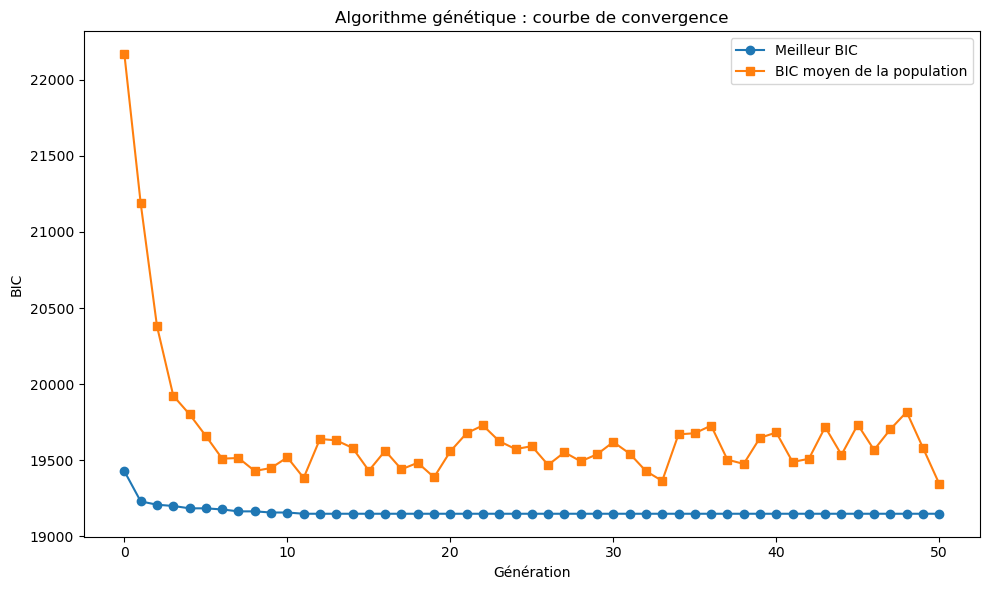

,meilleur_BIC,BIC_moyen,écart
génération,,,
0,19427.41,22168.10,2740.70
1,19229.22,21188.99,1959.76
2,19207.25,20380.58,1173.33
3,19198.96,19923.36,724.40
4,19183.51,19801.32,617.82
5,19183.41,19659.15,475.74
6,19176.06,19510.03,333.97
7,19163.48,19514.24,350.77
8,19163.48,19428.89,265.41


In [30]:
# Question 8.4 :

plt.figure(figsize=(10, 6))  # On fixe la taille de la figure.
plt.plot(historique_ga.index, historique_ga["meilleur_BIC"], marker="o", label="Meilleur BIC")  # On trace le meilleur BIC par génération.
plt.plot(historique_ga.index, historique_ga["BIC_moyen"], marker="s", label="BIC moyen de la population")  # On trace le BIC moyen par génération.
plt.xlabel("Génération")  # On nomme l'axe horizontal.
plt.ylabel("BIC")  # On nomme l'axe vertical.
plt.title("Algorithme génétique : courbe de convergence")  # On ajoute le titre.
plt.legend()  # On affiche la légende.
plt.tight_layout()  # On ajuste les marges.
plt.show()  # On affiche la figure.

tableau_bic = historique_ga.copy()  # On copie l'historique des générations.
tableau_bic["écart"] = tableau_bic["BIC_moyen"] - tableau_bic["meilleur_BIC"]  # On calcule l'écart entre le BIC moyen et le meilleur.
tableau_bic.round(2)  # On affiche le tableau récapitulatif.

**Meilleur BIC.** Il ne remonte jamais, grâce à l'élitisme qui recopie le meilleur individu d'une génération à la suivante. Il descend par paliers, de $19\,427$ (population initiale aléatoire) à $19\,147{,}81$ à la génération 11, puis il ne bouge plus jusqu'à la génération 50 : l'algorithme a convergé.

**BIC moyen.** Il baisse très vite pendant les premières générations, de $22\,168$ à environ $19\,500$ : la sélection par tournoi élimine rapidement les mauvais individus. Il oscille ensuite autour de $19\,570$ sans rejoindre le meilleur BIC. Cet écart est dû à la mutation : à chaque génération, certains enfants perdent une variable importante, ce qui fait fortement monter leur BIC et tire la moyenne vers le haut.

**Lecture.** L'écart entre les deux courbes montre que la population garde de la diversité, ce qui permet de continuer à explorer. Ici 50 générations sont largement suffisantes : une vingtaine aurait donné le même résultat, comme observé en Q8.3.

## Partie 9 Bilan comparatif et discussion critique

In [29]:
# Question 9.1 

from sklearn.metrics import mean_squared_error, r2_score  # On importe les métriques d'évaluation.

def evaluer(nom, y_pred, nb_variables):  # On définit l'évaluation d'une méthode sur le test.
    return {"Méthode": nom, "Nb variables": nb_variables, "RMSE test": np.sqrt(mean_squared_error(y_test, y_pred)), "R² test": r2_score(y_test, y_pred)}  # On renvoie la RMSE et le R² de test.

sous_ensembles = {"Modèle complet": variables, "Best subset": variables_best_subset, "Forward": variables_forward, "Backward": variables_backward, "Algorithme génétique": variables_ga}  # On regroupe les sous-ensembles de variables.

resultats = []  # On prépare la liste des résultats.
for nom, liste in sous_ensembles.items():  # On parcourt les méthodes de sélection.
    modele = LinearRegression().fit(X_train[liste], y_train)  # On ajuste le modèle sur l'apprentissage.
    resultats.append(evaluer(nom, modele.predict(X_test[liste]), len(liste)))  # On évalue le modèle sur le test.

resultats.append(evaluer("Ridge", best_ridge.predict(X_test), len(variables)))  # On évalue le modèle Ridge sur le test.
resultats.append(evaluer("Lasso", best_lasso.predict(X_test), len(variables_lasso)))  # On évalue le modèle Lasso sur le test.

ordre = ["Modèle complet", "Best subset", "Forward", "Backward", "Ridge", "Lasso", "Algorithme génétique"]  # On fixe l'ordre des lignes.
bilan = pd.DataFrame(resultats).set_index("Méthode").loc[ordre]  # On range les résultats dans un tableau.
bilan.round(4)  # On affiche le tableau récapitulatif.

,Nb variables,RMSE test,R² test
Méthode,,,
Modèle complet,25,2.7478,0.7651
Best subset,9,2.7489,0.7649
Forward,11,2.7471,0.7652
Backward,11,2.7471,0.7652
Ridge,25,2.7479,0.7651
Lasso,15,2.7479,0.7651
Algorithme génétique,9,2.7489,0.7649


**Question 9.2 :** 

**(a) Meilleure capacité prédictive pure : forward ou backward.** Ils obtiennent la RMSE de test la plus faible ($2{,}7471$) et le $R^2$ le plus élevé ($0{,}7652$). L'avantage est toutefois infime : l'écart avec la moins bonne méthode est inférieur à $0{,}002$ k€, donc les sept méthodes sont équivalentes en prédiction sur ces données.

**(b) Interprétabilité : best subset (ou algorithme génétique, qui donne le même modèle).** Il ne garde que 9 variables pour la même qualité de prédiction, avec une seule variable du groupe « taille », ce qui supprime la colinéarité. Ses coefficients sont ceux des moindres carrés, sans rétrécissement : ils se lisent directement comme l'effet de chaque variable sur le prix.

**(c) Compromis coût / qualité de sélection : sélection ascendante (forward).** Elle ajuste au plus $1 + p(p+1)/2 = 326$ modèles, contre $2^{25} \approx 33{,}5$ millions pour une recherche exhaustive, et elle retrouve les 9 variables principales dès ses 9 premières étapes. Elle est de plus déterministe et sans hyperparamètre à régler, contrairement à l'algorithme génétique, qui trouve la même solution que le best subset en $2\,550$ évaluations mais dépend du taux de mutation (Q8.3).